Data Preprocessing:

Step 1 -> Combine Different Categories of Pakistani Recipes together
Step 2 -> Remove Duplicate Recipes that belong to the same category
Step 3 -> Merge the Different Categories of same recipes

In [10]:
import pandas as pd

# Load the combined Excel file with recipes
file_path = 'combined_data.xlsx'  # Change this to your file path
data = pd.read_excel(file_path)

# Step 1: Identify duplicates based on both 'Recipe Name' and 'Category'
duplicates = data[data.duplicated(subset=['Recipe Name', 'Category'], keep=False)]

# Step 2: Count the duplicates
duplicate_counts = duplicates.groupby(['Recipe Name', 'Category']).size().reset_index(name='Count')

# Print the duplicate recipes and their counts
if not duplicate_counts.empty:
    print("Duplicate Recipes and Their Counts (with Same Category):")
    print(duplicate_counts)
else:
    print("No duplicate recipes found with the same category.")

# Step 3: Remove rows with duplicate recipe names within the same category
cleaned_data = data.drop_duplicates(subset=['Recipe Name', 'Category'], keep=False)

# Save the cleaned data to a new Excel file
cleaned_file_path = 'unique_recipes.xlsx'  # Change this to your desired output file path
cleaned_data.to_excel(cleaned_file_path, index=False)



Duplicate Recipes and Their Counts (with Same Category):
                  Recipe Name     Category  Count
0              Achari Biryani         Rice      3
1          Achari Gosht Pulao         Rice      2
2                Achari Pulao   Vegetarian      2
3                Akhrot Halwa      Dessert      2
4    Almond & Coconut Pudding      Dessert      2
..                        ...          ...    ...
386             Zafrani Pulao         Rice      2
387                     Zarda      Dessert      2
388                     Zarda         Rice      3
389             Zinger Burger  Street Food      3
390             Zucchini Rice   Vegetarian      3

[391 rows x 3 columns]


Visual Representation on Categories that have Duplicates

Duplicate Recipes and Their Counts (by Category):
      Category  Count
0    BBQ-GRILL     45
1    Breakfast     28
2      Dessert     61
3       Drinks     27
4         Meat    117
5         Rice    167
6      Seafood    273
7  Street Food    116
8   Vegetarian    176


C:\Users\user\AppData\Local\Temp\ipykernel_2016\739960562.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=duplicate_counts, x='Category', y='Count', palette=colors)


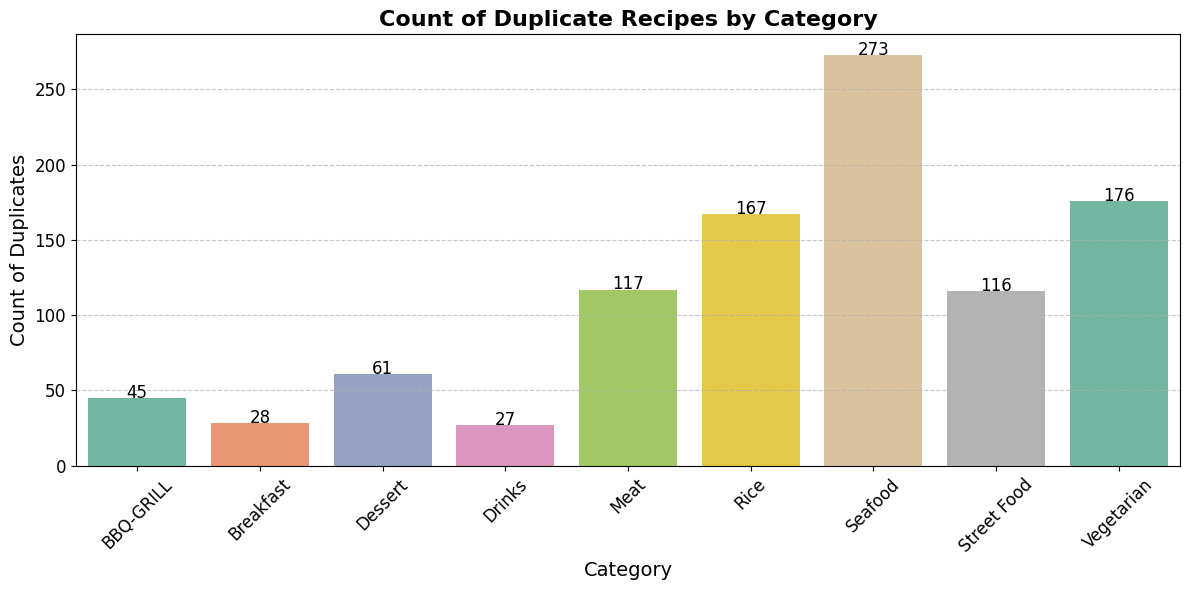

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the combined Excel file with recipes
file_path = 'combined_data.xlsx'  # Change this to your file path
data = pd.read_excel(file_path)

# Step 1: Identify duplicates based on both 'Recipe Name' and 'Category'
duplicates = data[data.duplicated(subset=['Recipe Name', 'Category'], keep=False)]

# Step 2: Count the duplicates
duplicate_counts = duplicates.groupby('Category').size().reset_index(name='Count')

# Print the duplicate recipes and their counts
if not duplicate_counts.empty:
    print("Duplicate Recipes and Their Counts (by Category):")
    print(duplicate_counts)
else:
    print("No duplicate recipes found with the same category.")

# Step 3: Create a pretty Seaborn bar plot
plt.figure(figsize=(12, 6))  # Set figure size

# Generate a color palette with different colors for each category
colors = sns.color_palette("Set2", len(duplicate_counts))  # Set2 palette for distinct colors

# Create a bar plot for duplicates by category
sns.barplot(data=duplicate_counts, x='Category', y='Count', palette=colors)
plt.title('Count of Duplicate Recipes by Category', fontsize=16, weight='bold')
plt.xlabel('Category', fontsize=14)
plt.ylabel('Count of Duplicates', fontsize=14)
plt.xticks(rotation=45, fontsize=12)  # Rotate x-axis labels for better visibility
plt.yticks(fontsize=12)

# Add data labels on top of the bars
for index, row in duplicate_counts.iterrows():
    plt.text(index, row['Count'] + 0.1, row['Count'], color='black', ha='center', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add grid lines for better readability
plt.tight_layout()  # Adjust layout to make room for rotated x labels
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_2016\3876938178.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Category', order=unique_categories, palette=colors)


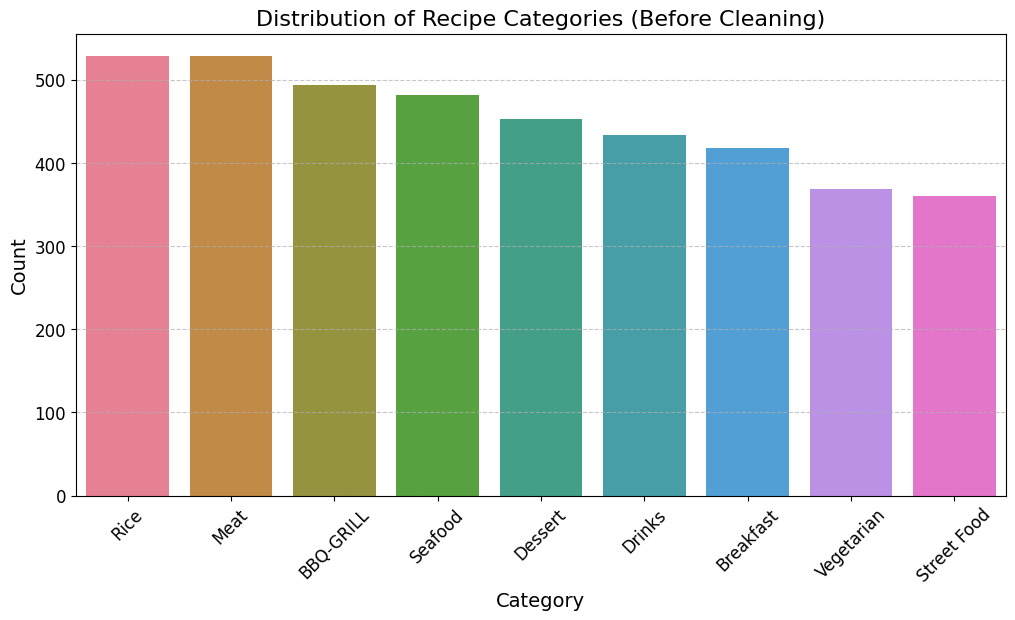

In [8]:
# Step 1: Visualize the distribution of recipe categories before cleaning
plt.figure(figsize=(12, 6))  # Set figure size

# Generate a color palette with different colors for each category
unique_categories = data['Category'].value_counts().index
colors = sns.color_palette("husl", len(unique_categories))  # Use the husl palette for distinct colors

# Create a count plot with categories on the x-axis and counts on the y-axis
sns.countplot(data=data, x='Category', order=unique_categories, palette=colors)
plt.title('Distribution of Recipe Categories (Before Cleaning)', fontsize=16)
plt.xlabel('Category', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(rotation=45, fontsize=12)  # Rotate x-axis labels for better visibility
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add grid lines for better readability
plt.show()



In [5]:
import pandas as pd

# Load the combined Excel file with recipes
file_path = 'combined_data.xlsx'  # Change this to your file path
data = pd.read_excel(file_path)

# Step 1: Identify duplicates based on 'Recipe Name'
duplicates = data[data.duplicated(subset='Recipe Name', keep=False)]

# Step 2: Merge categories for duplicate recipes
if not duplicates.empty:
    # Create a DataFrame that merges categories for each recipe name
    merged_categories = (
        duplicates.groupby('Recipe Name')
        .agg(lambda x: '/'.join(sorted(set(x))) if x.name == 'Category' else x.iloc[0])
        .reset_index()
    )
    
    # Step 3: Drop original duplicates from the main data
    non_duplicates = data[~data['Recipe Name'].isin(duplicates['Recipe Name'])]

    # Step 4: Combine non-duplicates with merged categories
    final_data = pd.concat([non_duplicates, merged_categories], ignore_index=True)
else:
    # If no duplicates found, use original data
    final_data = data.copy()

# Step 5: Save the merged data to a new Excel file
cleaned_file_path = 'merged_recipes.xlsx'  # Change this to your desired output file path
final_data.to_excel(cleaned_file_path, index=False)

print("Merged recipes saved to:", cleaned_file_path)


Merged recipes saved to: merged_recipes.xlsx


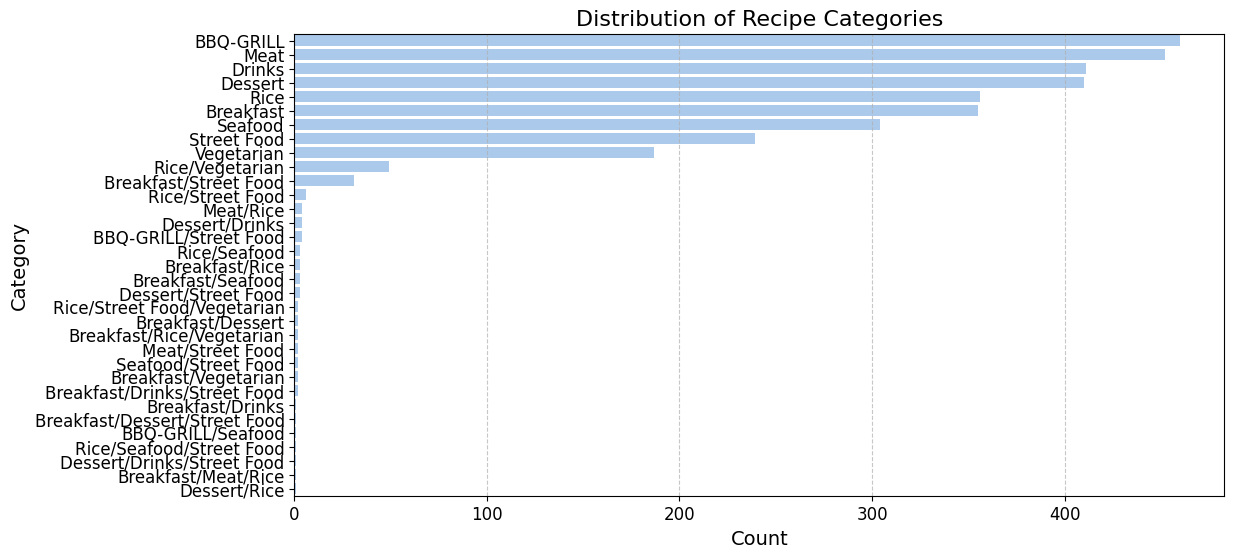

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

#Step 6: Visualize the distribution of recipe categories
plt.figure(figsize=(12, 6))  # Set figure size

# Set a beautiful seaborn palette
sns.set_palette("pastel")  # Change to your preferred color palette

# Create a count plot with improved aesthetics
sns.countplot(data=final_data, y='Category', order=final_data['Category'].value_counts().index)
plt.title('Distribution of Recipe Categories', fontsize=16)
plt.xlabel('Count', fontsize=14)
plt.ylabel('Category', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)  # Add grid lines for better readability
plt.show()